# How closely each motif pipeline tracks population spiking

Mouse 720762, deep prelimbic (PL5): 63 well-isolated units, and the PL5 LFP motifs from three pipelines.

| Pipeline | Motif signals used as predictors, per state |
|---|---|
| Original (strict, 1 Nov) | Expression of the strict motif of that state (awake: 1 motif; isoflurane: none found) |
| Relaxed (last week) | Expression of that state's relaxed motif and the full-recording relaxed motif |
| Tracker: expression | Expression of the 9 library motifs (residual around the moving baseline) |
| Tracker: baseline | Baseline position of the 9 library motifs (the slow part) |
| Tracker: both | Both (18 signals) |
| All 10 bands | Every band's power (reference: what any linear readout of the spectrum can do) |

**Neural targets**, per state on spontaneous seconds (stimulus blocks ±5 s excluded):
- **Population rate:** summed spikes of all 63 units, 1-s bins, Gaussian smoothing σ = 1 s.
- **Ensembles:** Mishler's `getClust` (ported to `src/get_clust.py`). Each unit's rate is squared then z-scored; the
  ensemble's activity is getClust's group support (share of members above zero × their mean).

**Score:** held-out R² of a ridge regression. Folds interleave 60-s blocks, so each fold samples the whole state;
10 s are trimmed at block edges. The null circularly shifts the target in time, which keeps both signals'
autocorrelation but breaks their alignment; 95th percentile shown. Then the same on the **fast part**: target and
predictors both detrended with the same 5-min local-linear baseline.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from src import motif_tracking as mt, spike_validation as sv
from src.get_clust import group_support
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-10_spike_validation"; OUT.mkdir(parents=True, exist_ok=True)
def save(fig, name): fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

res = mt.load(REPO / "data" / "processed" / "motif_tracking" / "720762" / "lfp_PL5.pkl")
sig = mt.prepare(NWB, "lfp_PL5", ("lfp", "probeF", "PL5"), res.config)
info, t = sig.info, sig.t
rate, unit_ids = sv.unit_rates(NWB, "PL5", t)
R = json.load(open(REPO / "data" / "out" / "2026-11-01_mouse720762" / "results.json"))
runs = {(r["window"], r["version"]): np.array(r["motifs"], float)[:, :r["n_motifs"]] for r in R["motif_runs"] if r["signal"] == "lfp_PL5"}
K = len(res.library)
E = res.second[[f"expr_M{i + 1}" for i in range(K)]].to_numpy()
Bm = res.second[[f"base_M{i + 1}" for i in range(K)]].to_numpy()
PIPES = ["Original (strict)", "Relaxed", "Tracker: expression", "Tracker: baseline", "Tracker: both", "All 10 bands"]
PCOL = {"Original (strict)": "#9AA5B1", "Relaxed": "#2F7F8F", "Tracker: expression": "#E0A030", "Tracker: baseline": "#C2504A",
        "Tracker: both": "#1D232B", "All 10 bands": "#D5DBE2"}
print(rate.shape[1], "units")

63 units


## 1. Ensembles (getClust) in each state

In [2]:
S = {}
for st, m in sv.state_masks(t, info).items():
    m = m & np.isfinite(E).all(1) & np.isfinite(Bm).all(1)
    clusters, stab, X = sv.ensembles(rate[:, :], m)
    Zs = sig.Z[m]; Zs = (Zs - Zs.mean(0)) / Zs.std(0)
    def proj(win, ver):
        A = runs.get((win, ver))
        return None if A is None or A.size == 0 else Zs @ (A / np.linalg.norm(A, axis=0))
    rel = [x for x in (proj(st, "relaxed"), proj("full", "relaxed")) if x is not None]
    feats = {"Original (strict)": proj(st, "strict"), "Relaxed": np.column_stack(rel) if rel else None,
             "Tracker: expression": E[m], "Tracker: baseline": Bm[m], "Tracker: both": np.column_stack([E[m], Bm[m]]),
             "All 10 bands": Zs}
    S[st] = dict(mask=m, clusters=clusters, stab=stab, X=X, feats=feats, targets=sv.ensemble_targets(X, clusters, rate[m]))
pd.DataFrame([{"state": st, "seconds": int(d["mask"].sum()), "ensembles": len(d["clusters"]),
               "sizes": [len(c) for c in d["clusters"]], "stability across 5 seeds (Jaccard)": d["stab"].round(2).tolist(),
               "units in an ensemble": int(sum(len(c) for c in d["clusters"]))} for st, d in S.items()]).set_index("state")

,seconds,ensembles,sizes,stability across 5 seeds (Jaccard),units in an ensemble
state,,,,,
awake,997,2,"[32, 6]","[0.98, 0.93]",38
isoflurane,1438,3,"[27, 25, 6]","[1.0, 1.0, 1.0]",58


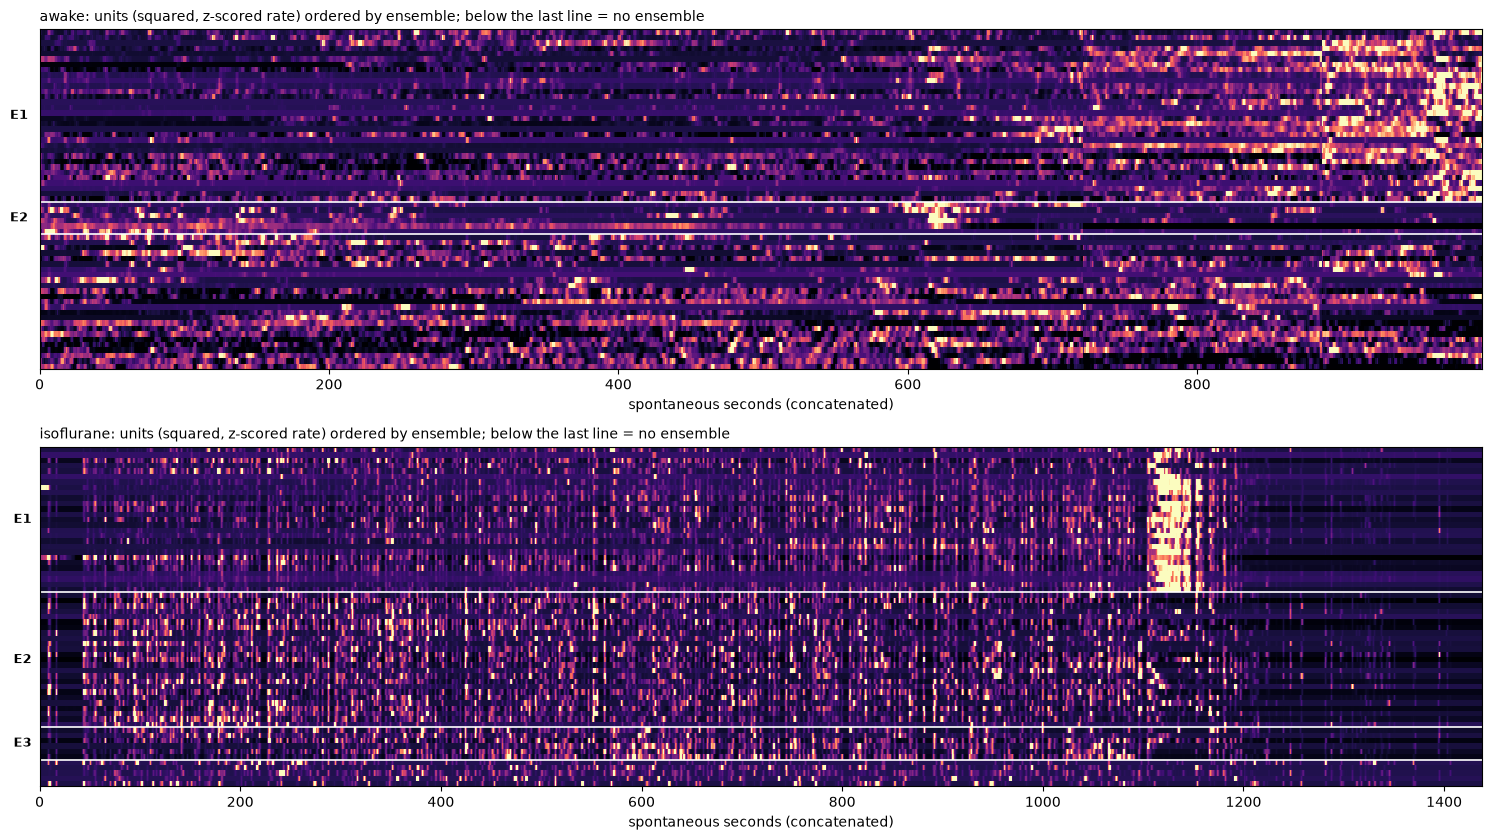

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5))
for ax, (st, d) in zip(axes, S.items()):
    tt = t[d["mask"]]; X = d["X"]
    order = np.concatenate(d["clusters"] + [np.setdiff1d(np.arange(X.shape[1]), np.concatenate(d["clusters"]))])
    ax.imshow(np.clip(X[:, order].T, -1, 3), aspect="auto", cmap="magma", interpolation="none",
              extent=[0, len(tt), len(order), 0])
    y0 = 0
    for i, c in enumerate(d["clusters"]):
        ax.axhline(y0 + len(c), color="white", lw=1.2)
        ax.text(-8, y0 + len(c) / 2, f"E{i + 1}", ha="right", va="center", fontsize=9, fontweight="bold")
        y0 += len(c)
    ax.set_title(f"{st}: units (squared, z-scored rate) ordered by ensemble; below the last line = no ensemble", loc="left", fontsize=10)
    ax.set_xlabel("spontaneous seconds (concatenated)"); ax.set_yticks([])
fig.tight_layout(); save(fig, "1_ensembles"); plt.show()

## 2. Held-out R² per pipeline

In [4]:
rows = []
for st, d in S.items():
    full = sv.evaluate(d["feats"], d["targets"], n_shift=100); full["part"] = "full"
    tt = t[d["mask"]]
    ff = {k: (None if v is None else sv.detrend(v, tt)) for k, v in d["feats"].items() if k not in ("Tracker: baseline", "Tracker: both")}
    fast = sv.evaluate(ff, {k: sv.detrend(v, tt) for k, v in d["targets"].items()}, n_shift=100); fast["part"] = "fast"
    for df in (full, fast):
        df.insert(0, "state", st); rows.append(df)
scores = pd.concat(rows, ignore_index=True)
scores.to_csv(OUT / "scores.csv", index=False)
scores.pivot_table(index=["state", "part", "target"], columns="pipeline", values="r2").reindex(columns=PIPES).round(2)

pipeline                               Original (strict)  Relaxed  \
state      part target                                              
awake      fast ensemble 1 (32 units)               0.00    -0.01   
                ensemble 2 (6 units)               -0.02    -0.11   
                population rate                     0.02     0.02   
           full ensemble 1 (32 units)               0.15     0.14   
                ensemble 2 (6 units)               -0.05    -0.12   
                population rate                     0.05     0.06   
isoflurane fast ensemble 1 (27 units)               0.00    -0.01   
                ensemble 2 (25 units)               0.00     0.02   
                ensemble 3 (6 units)                0.00     0.02   
                population rate                     0.00    -0.02   
           full ensemble 1 (27 units)               0.00    -0.06   
                ensemble 2 (25 units)               0.00     0.04   
                ensemble 3 (6 units)                0.00     0.08   
                population rate                     0.00     0.22   

pipeline                               Tracker: expression  Tracker: baseline  \
state      part target                                                          
awake      fast ensemble 1 (32 units)                -0.11                NaN   
                ensemble 2 (6 units)                 -0.05                NaN   
                population rate                      -0.04                NaN   
           full ensemble 1 (32 units)                -0.29               0.73   
                ensemble 2 (6 units)                 -0.06              -0.17   
                population rate                      -0.23               0.05   
isoflurane fast ensemble 1 (27 units)                 0.08                NaN   
                ensemble 2 (25 units)                 0.09                NaN   
                ensemble 3 (6 units)                  0.08                NaN   
                population rate                       0.52                NaN   
           full ensemble 1 (27 units)                -0.08              -0.14   
                ensemble 2 (25 units)                 0.08               0.04   
                ensemble 3 (6 units)                  0.07               0.05   
                population rate                       0.35               0.29   

pipeline                               Tracker: both  All 10 bands  
state      part target                                              
awake      fast ensemble 1 (32 units)            NaN         -0.14  
                ensemble 2 (6 units)             NaN         -0.04  
                population rate                  NaN         -0.04  
           full ensemble 1 (32 units)           0.71         -0.05  
                ensemble 2 (6 units)           -0.18         -0.08  
                population rate                -0.05         -0.13  
isoflurane fast ensemble 1 (27 units)            NaN          0.17  
                ensemble 2 (25 units)            NaN          0.08  
                ensemble 3 (6 units)             NaN          0.07  
                population rate                  NaN          0.56  
           full ensemble 1 (27 units)           0.03          0.07  
                ensemble 2 (25 units)           0.13          0.07  
                ensemble 3 (6 units)            0.13          0.12  
                population rate                 0.67          0.68

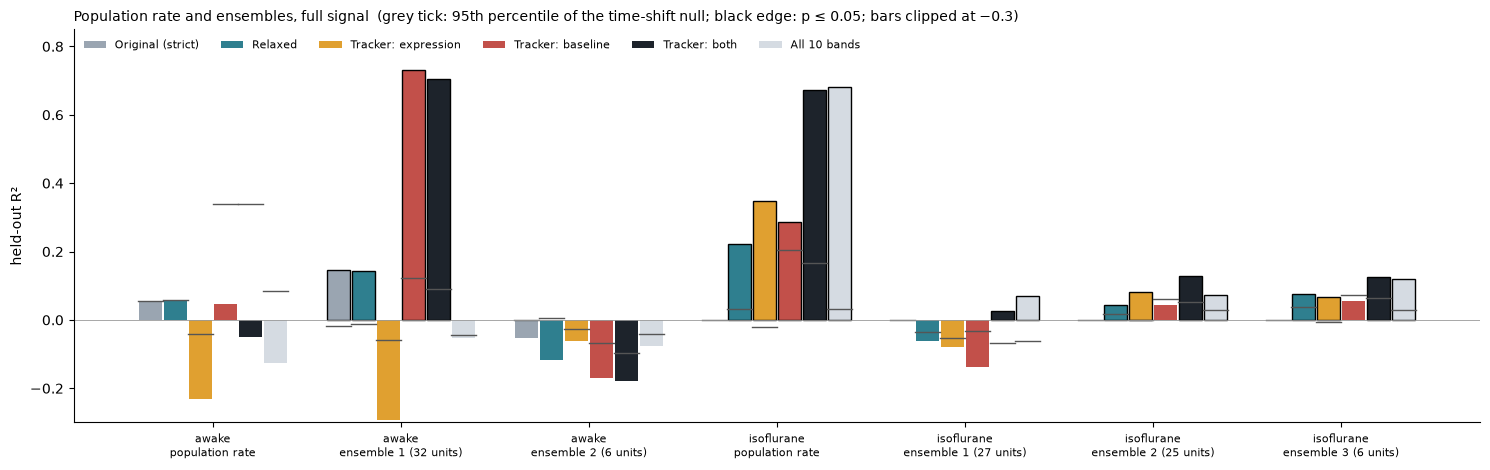

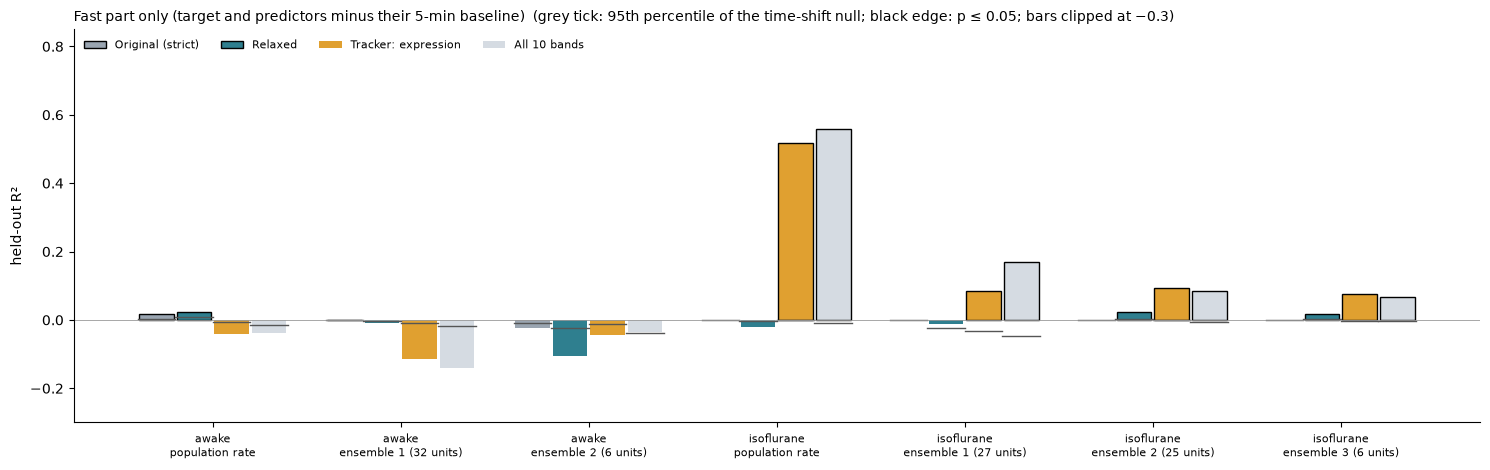

In [5]:
def bars(part, fname, title):
    sub = scores[scores.part == part]
    tgs = [(st, tg) for st in S for tg in S[st]["targets"]]
    fig, ax = plt.subplots(figsize=(15, 4.8))
    pipes = [p for p in PIPES if p in sub.pipeline.unique()]
    w = 0.8 / len(pipes)
    for j, p in enumerate(pipes):
        for i, (st, tg) in enumerate(tgs):
            r = sub[(sub.state == st) & (sub.target == tg) & (sub.pipeline == p)]
            if not len(r): continue
            r = r.iloc[0]
            x = i + (j - (len(pipes) - 1) / 2) * w
            ax.bar(x, max(r.r2, -0.3), w * 0.92, color=PCOL[p], label=p if i == 0 else None,
                   edgecolor="k" if r.p <= 0.05 and r.r2 > 0 else "none", lw=1)
            ax.plot([x - w / 2, x + w / 2], [r.null95] * 2, color="#555555", lw=1)
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xticks(range(len(tgs)), [f"{st}\n{tg}" for st, tg in tgs], fontsize=8)
    ax.set_ylabel("held-out R²"); ax.set_ylim(-0.3, 0.85)
    ax.legend(fontsize=8, ncol=len(pipes), loc="upper left", frameon=False)
    ax.set_title(title + "  (grey tick: 95th percentile of the time-shift null; black edge: p ≤ 0.05; bars clipped at −0.3)", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); save(fig, fname); plt.show()

bars("full", "2_r2_full", "Population rate and ensembles, full signal")
bars("fast", "2_r2_fast", "Fast part only (target and predictors minus their 5-min baseline)")

## 3. What the predictions look like (held-out)

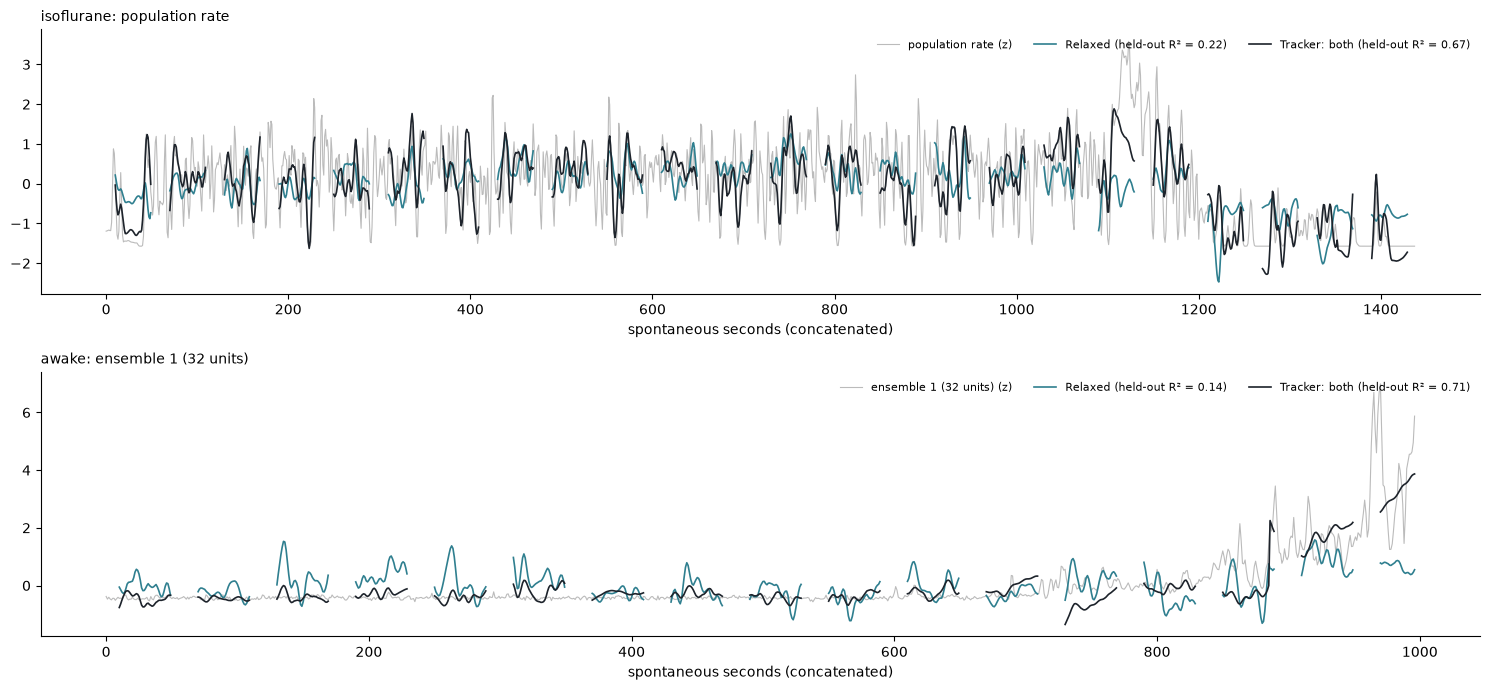

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
for ax, (st, tg, picks) in zip(axes, [("isoflurane", "population rate", ["Relaxed", "Tracker: both"]),
                                      ("awake", [k for k in S["awake"]["targets"] if k.startswith("ensemble 1")][0], ["Relaxed", "Tracker: both"])]):
    d = S[st]; y = sv.zscore(d["targets"][tg])
    x = np.arange(y.size)
    ax.plot(x, y, color="#BBBBBB", lw=0.8, label=f"{tg} (z)")
    for p in picks:
        pr = sv.cv_predict(d["feats"][p], y)
        r2 = scores[(scores.state == st) & (scores.target == tg) & (scores.pipeline == p) & (scores.part == "full")].r2.iloc[0]
        ax.plot(x, pr, color=PCOL[p], lw=1.2, label=f"{p} (held-out R² = {r2:.2f})")
    ax.set_title(f"{st}: {tg}", loc="left", fontsize=10); ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper right")
    ax.set_xlabel("spontaneous seconds (concatenated)"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); save(fig, "3_predictions"); plt.show()

## 4. Mishler-style pole contrast

For each pipeline's main motif per state: z-scored target in + pole seconds minus − pole seconds (sign of the
expression), with a two-sided time-shift p-value. Tracker: M1 (broadband) and M2.

In [7]:
rng = np.random.default_rng(0)
prow = []
for st, d in S.items():
    cand = {"Original (strict)": d["feats"]["Original (strict)"], "Relaxed (state motif)": None if d["feats"]["Relaxed"] is None else d["feats"]["Relaxed"][:, :1],
            "Tracker M1 expression": E[d["mask"]][:, :1], "Tracker M2 expression": E[d["mask"]][:, 1:2]}
    for name, F in cand.items():
        for tg, y in d["targets"].items():
            if F is None:
                prow.append({"state": st, "motif": name, "target": tg, "diff (z)": np.nan, "p": np.nan}); continue
            diff, p = sv.pole_contrast(F[:, 0], y, rng)
            prow.append({"state": st, "motif": name, "target": tg, "diff (z)": diff, "p": p})
poles = pd.DataFrame(prow); poles.to_csv(OUT / "pole_contrast.csv", index=False)
poles.pivot_table(index=["state", "target"], columns="motif", values="diff (z)").round(2)

motif                             Original (strict)  Relaxed (state motif)  \
state      target                                                            
awake      ensemble 1 (32 units)               0.63                   0.62   
           ensemble 2 (6 units)               -0.07                  -0.07   
           population rate                     0.48                   0.47   
isoflurane ensemble 1 (27 units)                NaN                   0.39   
           ensemble 2 (25 units)                NaN                   0.09   
           ensemble 3 (6 units)                 NaN                   0.46   
           population rate                      NaN                   0.81   

motif                             Tracker M1 expression  Tracker M2 expression  
state      target                                                               
awake      ensemble 1 (32 units)                   0.13                   0.01  
           ensemble 2 (6 units)                    0.16                  -0.07  
           population rate                        -0.00                  -0.08  
isoflurane ensemble 1 (27 units)                   0.38                  -0.04  
           ensemble 2 (25 units)                   0.52                   0.13  
           ensemble 3 (6 units)                    0.39                  -0.15  
           population rate                         0.93                   0.26

In [8]:
poles.pivot_table(index=["state", "target"], columns="motif", values="p").round(3)

motif                             Original (strict)  Relaxed (state motif)  \
state      target                                                            
awake      ensemble 1 (32 units)              0.001                  0.001   
           ensemble 2 (6 units)               0.759                  0.771   
           population rate                    0.001                  0.001   
isoflurane ensemble 1 (27 units)                NaN                  0.017   
           ensemble 2 (25 units)                NaN                  0.647   
           ensemble 3 (6 units)                 NaN                  0.004   
           population rate                      NaN                  0.001   

motif                             Tracker M1 expression  Tracker M2 expression  
state      target                                                               
awake      ensemble 1 (32 units)                  0.458                  0.947  
           ensemble 2 (6 units)                   0.282                  0.612  
           population rate                        0.992                  0.414  
isoflurane ensemble 1 (27 units)                  0.001                  0.765  
           ensemble 2 (25 units)                  0.001                  0.045  
           ensemble 3 (6 units)                   0.001                  0.039  
           population rate                        0.001                  0.005

## Conclusions

**Ensembles.** getClust finds 2 ensembles while awake (32 and 6 units) and 3 under isoflurane (27, 25 and 6), stable
across 5 random seeds (Jaccard 0.93–1.0). 38 of 63 units are in an awake ensemble; 58 under isoflurane.

**Isoflurane: the tracker tracks spiking, the binned versions barely do.**
- Population rate, held-out R²: original none (no isoflurane motif), relaxed 0.22, tracker 0.67, all 10 bands 0.68
  (null 95th percentile ≤ 0.21).
- Fast part only: tracker expression 0.52, relaxed −0.02, all bands 0.56. So the tracker's motif expression carries
  nearly all of the moment-to-moment coupling a linear readout of the spectrum can find, and relaxed carries none.
- Pole contrast: + vs − pole of tracker M1 separates population rate by 0.93 z and all three ensembles by 0.38–0.52 z
  (p = 0.001); the relaxed isoflurane motif gives 0.81 z on population rate but 0.09–0.46 on ensembles.
- **Caveat:** M1 is the broadband motif, and broadband LFP power partly reflects local spiking itself. The tracker
  matches the full spectrum here; it doesn't beat it.

**Awake: mixed.**
- The strict/relaxed awake motif's poles separate population rate (0.48 z) and the large ensemble (0.63 z), p = 0.001.
  The tracker's motifs don't (|diff| ≤ 0.16): the tracker only partly recovers that awake motif.
- The tracker's baselines explain the large awake ensemble (R² 0.73, null 0.12), but mostly through one slow ramp in
  the minutes before induction; treat it as a single event.
- Nothing tracks the awake population rate second by second (fast-part R² ≤ 0.02).

**Limits.** Motifs were detected on the same session; folds are held out in time but not in detection. One region,
one mouse. Linear readout at 1 Hz.